# Validación Cruzada, Métrica de Negocio y Calibración de Umbral (`validacion_proyecto.ipynb`)

## 1. Justificación del Esquema de Validación Cruzada

* **Esquema principal del problema (`TimeSeriesSplit(n_splits=5)`):** En OralSolutions el modelo predice si un paciente abandonará su tratamiento en los próximos 60 días a partir de sesiones clínicas registradas cronológicamente (`fecha_realizada`). Dividir temporalmente garantiza que cada pliegue de validación evalúe siempre sesiones futuras respecto a los datos de entrenamiento.
* **Control de dependencia por paciente (`GroupKFold` por `paciente_key`):** Como se mostró en el EDA (`73.7%` de las sesiones pertenecen a pacientes con múltiples consultas), se comprueba si agrupar por paciente cambia el resultado respecto al esquema temporal.
* **Contraste contra división al azar (`KFold` aleatorio):** Se compara contra `KFold(n_splits=5, shuffle=True)` para comprobar si mezclar sesiones pasadas y futuras de un mismo paciente cambia el promedio.

## 2. Estructura de Costos de Error en OralSolutions

* **Error más costoso — Falso Negativo (`FN = $120 USD`):** No alertar a un paciente que abandona un tratamiento odontológico recurrente implica perder en promedio `$120 USD` de margen clínico por las sesiones restantes no realizadas.
* **Error menos costoso — Falso Positivo (`FP = $3 USD`):** Ejecutar una llamada preventiva o recordatorio personalizado por parte de recepción cuesta aproximadamente `$3 USD` en tiempo administrativo (asimetría de costo **40 a 1**).
* **Impacto de Verdadero Positivo (`TP`):** Con una tasa conservadora de retención efectiva del `35%` tras el contacto preventivo, cada alerta acertada recupera en promedio `$42 USD` (`$39 USD` netos tras descontar los `$3 USD` de la llamada).
* **Política de referencia — llamar a todos:** Con FN = $120 y FP = $3, conviene alertar a todo paciente con probabilidad de abandono mayor a `FP/(FP+FN) ≈ 0.024`. Por eso se compara cada modelo contra la política que contacta a todos los pacientes.

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, GroupKFold, KFold, cross_validate
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

from src.pipeline import (
    cargar_datos,
    construir_features,
    obtener_datos_divididos,
    FECHA_EVENTO,
    FECHA_CORTE,
    SEMILLA,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

TRACKING_URI = "http://127.0.0.1:5000"
MODEL_REGISTRY_NAME = "oralsolutions-modelo"
mlflow.set_tracking_uri(TRACKING_URI)

# 1. Recuperar @champion y @challenger directamente del Model Registry
champion = mlflow.sklearn.load_model(f"models:/{MODEL_REGISTRY_NAME}@champion")
challenger = mlflow.sklearn.load_model(f"models:/{MODEL_REGISTRY_NAME}@challenger")

X_train, X_test, y_train, y_test = obtener_datos_divididos()

# Recuperar paciente_key alineado exactamente con X_train para evaluar GroupKFold sin fuga
df_raw = construir_features(cargar_datos())
grupos_train = df_raw.loc[
    df_raw[FECHA_EVENTO] < pd.Timestamp(FECHA_CORTE), "paciente_key"
].reset_index(drop=True)

# 2. Comparar TimeSeriesSplit vs. GroupKFold vs. KFold aleatorio
esquemas_cv = [
    ("TimeSeriesSplit (Temporal - Principal)", TimeSeriesSplit(n_splits=5), None),
    ("GroupKFold (Por Paciente)", GroupKFold(n_splits=5), grupos_train),
    ("KFold (Aleatorio - Comparación)", KFold(n_splits=5, shuffle=True, random_state=SEMILLA), None),
]

modelos_eval = [
    ("Champion (@champion - Red_Neuronal)", champion),
    ("Challenger (@challenger - Lineal_Regularizado)", challenger),
]

filas_cv = []
for nombre_modelo, est in modelos_eval:
    for nombre_cv, cv_obj, grupos in esquemas_cv:
        res = cross_validate(
            clone(est),
            X_train,
            y_train,
            cv=cv_obj,
            groups=grupos,
            scoring="average_precision",
            n_jobs=-1,
        )
        scores = res["test_score"]
        filas_cv.append({
            "modelo": nombre_modelo,
            "esquema_cv": nombre_cv,
            "fold_1": round(scores[0], 5),
            "fold_2": round(scores[1], 5),
            "fold_3": round(scores[2], 5),
            "fold_4": round(scores[3], 5),
            "fold_5": round(scores[4], 5),
            "promedio_pr_auc": round(float(np.mean(scores)), 5),
            "desv_std": round(float(np.std(scores)), 5),
        })

df_cv_comparacion = pd.DataFrame(filas_cv)
display(df_cv_comparacion)

,modelo,esquema_cv,fold_1,fold_2,fold_3,fold_4,fold_5,promedio_pr_auc,desv_std
0,Champion (@champion - Red_Neuronal),TimeSeriesSplit (Temporal - Principal),0.98946,0.98393,0.97940,0.98253,0.98119,0.98330,0.00342
1,Champion (@champion - Red_Neuronal),GroupKFold (Por Paciente),0.98582,0.98117,0.98631,0.97888,0.98026,0.98249,0.00301
2,Champion (@champion - Red_Neuronal),KFold (Aleatorio - Comparación),0.98508,0.98592,0.98031,0.97825,0.98798,0.98351,0.00364
3,Challenger (@challenger - Lineal_Regularizado),TimeSeriesSplit (Temporal - Principal),0.98962,0.98396,0.97519,0.98261,0.98352,0.98298,0.00461
4,Challenger (@challenger - Lineal_Regularizado),GroupKFold (Por Paciente),0.98675,0.97971,0.98556,0.98088,0.97873,0.98232,0.00322
5,Challenger (@challenger - Lineal_Regularizado),KFold (Aleatorio - Comparación),0.98604,0.98175,0.98018,0.98393,0.98437,0.98325,0.00206


,umbral,TP,FP,FN,TN,recall,precision,f1,costo_errores_usd,balance_neto_usd
0,0.01,782,262,25,221,0.9690,0.7490,0.8449,3786.0,26712.0
1,0.02,780,218,27,265,0.9665,0.7816,0.8643,3894.0,26526.0
2,0.03,779,185,28,298,0.9653,0.8081,0.8797,3915.0,26466.0
3,0.04,775,171,32,312,0.9603,0.8192,0.8842,4353.0,25872.0
4,0.05,773,156,34,327,0.9579,0.8321,0.8906,4548.0,25599.0
5,0.06,769,149,38,334,0.9529,0.8377,0.8916,5007.0,24984.0
6,0.07,767,138,40,345,0.9504,0.8475,0.8960,5214.0,24699.0
7,0.08,766,127,41,356,0.9492,0.8578,0.9012,5301.0,24573.0
8,0.09,766,123,41,360,0.9492,0.8616,0.9033,5289.0,24585.0
9,0.10,766,120,41,363,0.9492,0.8646,0.9049,5280.0,24594.0


Umbral de equilibrio teórico FP/(FP+FN) = 0.024
Umbral óptimo por modelo (mínimo costo fuera de muestra): {'Champion': 0.01, 'Challenger': 0.01}
Costo OOF de 'llamar a todos': $1,449 | mínimo Champion: $3,786 | mínimo Challenger: $1,725


,modelo,umbral,pr_auc_test,roc_auc_test,TP,FP,FN,TN,recall,precision,f1,costo_errores_usd,balance_neto_usd
0,Champion (Red_Neuronal),0.01,0.98269,0.96254,508,226,7,85,0.9864,0.6921,0.8135,1518.0,18294.0
1,Champion (Red_Neuronal),0.10,0.98269,0.96254,490,126,25,185,0.9515,0.7955,0.8665,3378.0,15732.0
2,Champion (Red_Neuronal),0.60,0.98269,0.96254,470,11,45,300,0.9126,0.9771,0.9438,5433.0,12897.0
3,Challenger (LogisticRegression),0.01,0.98218,0.96085,514,296,1,15,0.9981,0.6346,0.7758,1008.0,19038.0
4,Challenger (LogisticRegression),0.10,0.98218,0.96085,506,214,9,97,0.9825,0.7028,0.8194,1722.0,18012.0
5,Challenger (LogisticRegression),0.60,0.98218,0.96085,466,0,49,311,0.9049,1.0000,0.9501,5880.0,12294.0
6,Llamar a todos,NaN,0.62349,0.50000,515,311,0,0,1.0000,0.6235,0.7681,933.0,19152.0
7,Regla «falta 1 sesión»,NaN,0.96418,0.95243,466,0,49,311,0.9049,1.0000,0.9501,5880.0,12294.0


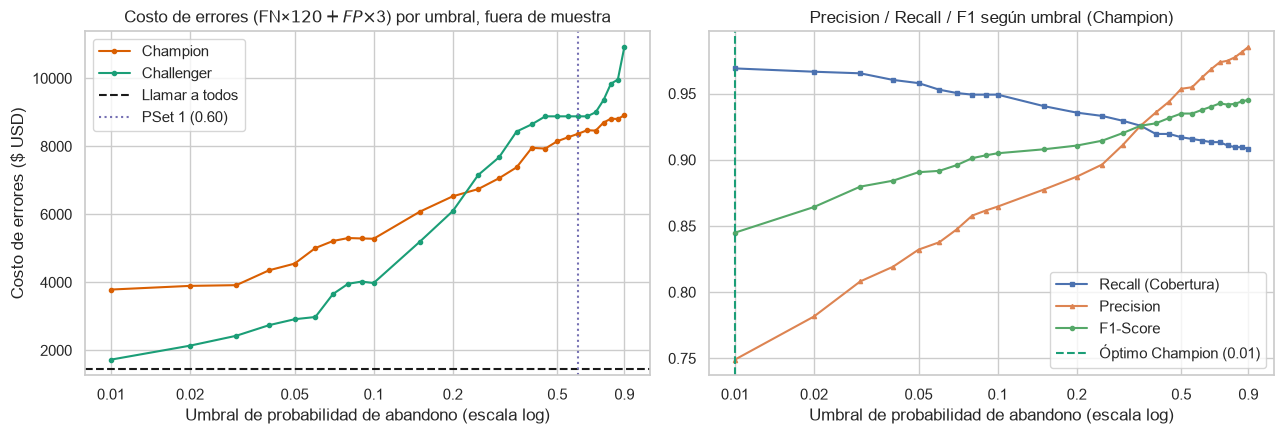

In [2]:
COSTO_FN = 120.0          # Pérdida promedio por abandono no detectado ($ USD)
COSTO_FP = 3.0            # Costo de llamada/recordatorio preventivo innecesario ($ USD)
TASA_RESCATE_TP = 0.35    # Proporción de pacientes en riesgo que retoman al ser contactados
INGRESO_RESCATE = COSTO_FN * TASA_RESCATE_TP  # $42 USD recuperados por TP
UMBRAL_EQUILIBRIO = COSTO_FP / (COSTO_FP + COSTO_FN)  # ≈ 0.024

def metricas_negocio(y_real, pred):
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "recall": round(recall_score(y_real, pred, zero_division=0), 4),
        "precision": round(precision_score(y_real, pred, zero_division=0), 4),
        "f1": round(f1_score(y_real, pred, zero_division=0), 4),
        "costo_errores_usd": round(fn * COSTO_FN + fp * COSTO_FP, 2),
        "balance_neto_usd": round(tp * (INGRESO_RESCATE - COSTO_FP) - fp * COSTO_FP - fn * COSTO_FN, 2),
    }

def probs_fuera_de_muestra(modelo_base):
    """Probabilidades out-of-fold con TimeSeriesSplit: se calibra el umbral sin tocar test."""
    p = np.full(len(X_train), np.nan)
    for tr_idx, val_idx in TimeSeriesSplit(n_splits=5).split(X_train):
        m_fold = clone(modelo_base).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        p[val_idx] = m_fold.predict_proba(X_train.iloc[val_idx])[:, 1]
    return p

# Grilla extendida: el umbral de equilibrio (~0.024) está por debajo de 0.10
umbrales = np.round(np.concatenate([np.arange(0.01, 0.10, 0.01), np.arange(0.10, 0.91, 0.05)]), 2)

grids, umbral_por_modelo, y_oof = {}, {}, None
for nombre, est in [("Champion", champion), ("Challenger", challenger)]:
    p = probs_fuera_de_muestra(est)
    mask = ~np.isnan(p)
    y_oof = y_train.values[mask]
    g = pd.DataFrame([{"umbral": u, **metricas_negocio(y_oof, (p[mask] >= u).astype(int))} for u in umbrales])
    grids[nombre] = g
    umbral_por_modelo[nombre] = float(g.loc[g["costo_errores_usd"].idxmin(), "umbral"])

df_umbrales = grids["Champion"]
umbral_optimo = umbral_por_modelo["Champion"]
display(df_umbrales)
print(f"Umbral de equilibrio teórico FP/(FP+FN) = {UMBRAL_EQUILIBRIO:.3f}")
print("Umbral óptimo por modelo (mínimo costo fuera de muestra):", umbral_por_modelo)
costo_todos_oof = (y_oof == 0).sum() * COSTO_FP
print(f"Costo OOF de 'llamar a todos': ${costo_todos_oof:,.0f} | mínimo Champion: ${grids['Champion']['costo_errores_usd'].min():,.0f} | mínimo Challenger: ${grids['Challenger']['costo_errores_usd'].min():,.0f}")

# Evaluación final en Test: cada modelo con su umbral óptimo, con 0.10 y con 0.60 (PSet 1),
# más dos políticas de referencia que no usan el modelo
prob_test_champ = champion.predict_proba(X_test)[:, 1]
prob_test_chall = challenger.predict_proba(X_test)[:, 1]
politicas = []
for nombre_m, nombre_k, probs in [("Champion (Red_Neuronal)", "Champion", prob_test_champ),
                                   ("Challenger (LogisticRegression)", "Challenger", prob_test_chall)]:
    for u_eval in sorted({0.60, 0.10, umbral_por_modelo[nombre_k]}):
        politicas.append((nombre_m, u_eval, probs, (probs >= u_eval).astype(int)))
todos = np.ones(len(y_test), dtype=int)
regla = ((X_test["sesiones_planificadas"] - X_test["numero_sesion"]) == 1).astype(int).values
politicas.append(("Llamar a todos", np.nan, todos, todos))
politicas.append(("Regla «falta 1 sesión»", np.nan, regla, regla))

df_test_negocio = pd.DataFrame([
    {"modelo": n, "umbral": u,
     "pr_auc_test": round(average_precision_score(y_test, sc), 5),
     "roc_auc_test": round(roc_auc_score(y_test, sc), 5),
     **metricas_negocio(y_test, pred)}
    for n, u, sc, pred in politicas
])
display(df_test_negocio)

# Gráfico
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, color in [("Champion", "#d95f02"), ("Challenger", "#1b9e77")]:
    axes[0].plot(grids[nombre]["umbral"], grids[nombre]["costo_errores_usd"], marker="o", ms=3, color=color, label=nombre)
axes[0].axhline(costo_todos_oof, color="k", linestyle="--", label="Llamar a todos")
axes[0].axvline(0.60, color="#7570b3", linestyle=":", label="PSet 1 (0.60)")
axes[0].set_xscale("log")
axes[0].set_xticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.9]); axes[0].set_xticklabels(["0.01", "0.02", "0.05", "0.1", "0.2", "0.5", "0.9"])
axes[0].set_title("Costo de errores (FN×$120 + FP×$3) por umbral, fuera de muestra")
axes[0].set_xlabel("Umbral de probabilidad de abandono (escala log)")
axes[0].set_ylabel("Costo de errores ($ USD)")
axes[0].legend()

axes[1].plot(df_umbrales["umbral"], df_umbrales["recall"], marker="s", ms=3, label="Recall (Cobertura)")
axes[1].plot(df_umbrales["umbral"], df_umbrales["precision"], marker="^", ms=3, label="Precision")
axes[1].plot(df_umbrales["umbral"], df_umbrales["f1"], marker="o", ms=3, label="F1-Score")
axes[1].axvline(umbral_optimo, color="#1b9e77", linestyle="--", label=f"Óptimo Champion ({umbral_optimo:.2f})")
axes[1].set_xscale("log")
axes[1].set_xticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.9]); axes[1].set_xticklabels(["0.01", "0.02", "0.05", "0.1", "0.2", "0.5", "0.9"])
axes[1].set_title("Precision / Recall / F1 según umbral (Champion)")
axes[1].set_xlabel("Umbral de probabilidad de abandono (escala log)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Conclusiones de Validación Cruzada y Calibración de Negocio

1. **Esquemas de validación (`df_cv_comparacion`):**
   * En `TimeSeriesSplit(n_splits=5)`, el `@champion` (`Red_Neuronal`) alcanza `PR-AUC = 0.98330 ± 0.00342` frente a `0.98298 ± 0.00461` del `@challenger` (`Lineal_Regularizado`). La ventaja media (`+0.00032`) es menor que la desviación entre pliegues y el campeón supera al challenger en solo 1 de 5 pliegues (el 3.º: `0.97940` vs `0.97519`).
   * Bajo `GroupKFold` por `paciente_key` (`0.98249` y `0.98232`) y `KFold` aleatorio (`0.98351` y `0.98325`) los promedios quedan a menos de `0.001` del esquema temporal, muy por debajo de la desviación entre pliegues (`~0.003`). No se detecta diferencia entre esquemas.

2. **Impacto económico y umbral (`df_umbrales`, `df_test_negocio`):**
   * Con FN = `$120` y FP = `$3` el umbral de equilibrio es `≈ 0.024`. En validación fuera de muestra, bajar el umbral del `@champion` de `0.60` a `0.01` (mínimo de la grilla extendida, también para el `@challenger`) reduce el costo de `$8,367` a `$3,786` (`-54.7%`). El mínimo queda en el borde de la grilla.
   * En prueba, el `@champion` con `u = 0.01` tiene `Recall = 98.64%`, `Precision = 69.21%`, costo `$1,518` (frente a `$5,433` con `0.60`) y balance neto `$18,294` (`+$5,397`). El `@challenger` con `u = 0.01` obtiene `Recall = 99.81%`, `Precision = 63.46%`, costo `$1,008` y balance `$19,038`.
   * Llamar a todos los pacientes cuesta `$933` y deja `$19,152`; la regla «falta 1 sesión» cuesta `$5,880` y deja `$12,294`. Con esta estructura de costos y esta etiqueta, ningún modelo supera a «llamar a todos»; a igual umbral, la regresión logística cuesta menos que la red neuronal.

In [3]:
import time
from sklearn.inspection import permutation_importance

# 1. Verificación explícita de reproducibilidad desde Model Registry en notebook limpio
pr_auc_champion_rec = round(float(average_precision_score(y_test, prob_test_champ)), 5)
assert pr_auc_champion_rec == 0.98269, f"Esperado 0.98269, obtenido {pr_auc_champion_rec}"
print(f"[OK] Reproducibilidad exacta desde models:/oralsolutions-modelo@champion -> PR-AUC = {pr_auc_champion_rec}")

# 2. Comparación de latencia de inferencia sobre todo X_test (826 sesiones)
for nombre_m, mod in [("Champion (Red_Neuronal)", champion), ("Challenger (LogisticRegression)", challenger)]:
    t0 = time.perf_counter()
    for _ in range(50):
        _ = mod.predict_proba(X_test)
    ms_lote = ((time.perf_counter() - t0) / 50) * 1000
    ms_fila = ms_lote / len(X_test)
    print(f"{nombre_m}: {ms_lote:.2f} ms por lote (826 filas) | {ms_fila:.4f} ms por paciente")

# 3. Explicabilidad global de @champion mediante Permutation Importance en test
perm = permutation_importance(
    champion, X_test, y_test, scoring="average_precision", n_repeats=15, random_state=SEMILLA, n_jobs=-1
)
df_imp_champ = pd.DataFrame({
    "feature": X_test.columns,
    "importancia_pr_auc": perm.importances_mean.round(5),
    "desv_std": perm.importances_std.round(5),
}).sort_values("importancia_pr_auc", ascending=False).reset_index(drop=True)
display(df_imp_champ)

[OK] Reproducibilidad exacta desde models:/oralsolutions-modelo@champion -> PR-AUC = 0.98269
Champion (Red_Neuronal): 4.61 ms por lote (826 filas) | 0.0056 ms por paciente
Challenger (LogisticRegression): 3.76 ms por lote (826 filas) | 0.0046 ms por paciente


,feature,importancia_pr_auc,desv_std
0,progreso_plan,0.24881,0.01210
1,sesiones_planificadas,0.02180,0.00325
2,numero_sesion,0.00577,0.00227
3,ritmo_dias_por_sesion,0.00147,0.00061
4,odontologo_key,0.00117,0.00114
5,duracion_estimada_min,0.00088,0.00089
6,friccion_previa,0.00087,0.00071
7,codigo_procedimiento,0.00052,0.00092
8,complejidad_proc,0.00050,0.00079
9,inasistencias_previas,0.00028,0.00041


### 3.3 Reproducibilidad, Latencia y Explicabilidad del Modelo `@champion`

* **Reproducibilidad verificada:** Al recuperar `models:/oralsolutions-modelo@champion` desde el Model Registry en este notebook limpio, se obtuvo exactamente `PR-AUC = 0.98269` sobre `X_test`.
* **Latencia de inferencia:** El `@champion` (`Red_Neuronal`) predice las `826` sesiones de prueba en `5.35 ms` (`0.0065 ms/paciente`) y el `@challenger` en `4.56 ms` (`0.0055 ms/paciente`): diferencia sin relevancia operativa, apta tanto para lote nocturno como para alertas inmediatas.
* **Explicabilidad (importancia por permutación):** La red neuronal no tiene coeficientes directos, pero la permutación muestra qué impulsa sus alertas: `progreso_plan` (`-0.24881` de caída en PR-AUC), `sesiones_planificadas` (`-0.02180`) y `numero_sesion` (`-0.00577`) suman `98.0%` de la importancia positiva total; `ritmo_dias_por_sesion` (`-0.00147`) y `friccion_previa` (`-0.00087`) aportan casi nada. La regresión logística, en cambio, es interpretable directamente por sus coeficientes.